<a href="https://colab.research.google.com/github/sazedAawal/Cuckoo/blob/main/Test_1_0_dataset_Manest_et_al_2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip -q install catboost scikit-learn pandas matplotlib

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Datasets retrieved from Manest et al. 2025(https://www.researchgate.net/publication/390306497_A_SURROGATE_MACHINE_LEARNING_METHOD_FOR_REAL-TIME_INDOOR_ACOUSTIC_ANALYSIS_A_CASE_STUDY_IN_AN_EDUCATIONAL_BUILDING)

In [7]:
df = pd.read_csv('/content/sample_data/dataset.csv')

In [8]:
print('Dataset shape: ', df.shape)
print(df.head())

Dataset shape:  (978, 58)
   Height 1  Height 2  X Dim  Y Dim  Population  Reciver pos  Source pos  WWR  \
0       2.0       4.0   11.0   10.0         100            6         0.8  0.6   
1       2.0       4.0   11.0   10.0         100            6         0.8  0.6   
2       2.0       4.0   11.0   10.0         100            6         0.8  0.6   
3       4.5       4.0   16.0    8.5          25            5         0.2  0.6   
4       2.5       4.5    8.0    7.0          75            1         0.6  0.8   

   Sound Power  Floor mat  ...  Definition6  Definition7      EDT0      EDT1  \
0            2          2  ...    83.562475    84.892039  1.359669  1.359996   
1            2          2  ...    83.562475    84.892039  1.359669  1.359996   
2            2          2  ...    81.702622    83.108774  1.339092  1.339203   
3            2          2  ...    60.864084    63.096835  2.075431  2.074844   
4            3          2  ...    65.831462    67.543246  1.374263  1.372354   

      

In [9]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor

features = [
    "Height 1", "Height 2", "X Dim", "Y Dim",
    "Population", "Reciver pos", "Source pos", "WWR",
    "Sound Power", "Floor mat", "wall mat", "win mat",
    "cell mat", "fur mat"
]

target = "RT0"

# Material codes and receiver positions are treated as categories.
categorical_features = [
    "Reciver pos", "Floor mat", "wall mat",
    "win mat", "cell mat", "fur mat"
]

X = df[features].copy()
y = df[target].copy()

# CatBoost handles categorical features as strings.
for col in categorical_features:
    X[col] = X[col].astype(str)

# Group identical input configurations together to reduce
# train/test leakage from repeated design scenarios.
groups = df[features].astype(str).agg("|".join, axis=1)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Features:", len(features))
print("Target:", target)

Training rows: 780
Testing rows: 198
Features: 14
Target: RT0


In [10]:
# Train the Model

model = CatBoostRegressor(
    iterations=700,
    depth=6,
    learning_rate=0.04,
    loss_function="RMSE",
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

model.fit(
    X_train,
    y_train,
    cat_features=categorical_features,
    eval_set=(X_test, y_test),
    early_stopping_rounds=100,
    verbose=100
)

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("\n--- TEST RESULTS ---")
print(f"MAE:  {mae:.4f} seconds")
print(f"RMSE: {rmse:.4f} seconds")
print(f"R²:   {r2:.4f}")


0:	learn: 0.4551866	test: 0.4322612	best: 0.4322612 (0)	total: 56.5ms	remaining: 39.5s
100:	learn: 0.0809281	test: 0.0870905	best: 0.0870905 (100)	total: 523ms	remaining: 3.1s
200:	learn: 0.0594468	test: 0.0727236	best: 0.0727236 (200)	total: 942ms	remaining: 2.34s
300:	learn: 0.0496822	test: 0.0691558	best: 0.0691446 (299)	total: 2.03s	remaining: 2.69s
400:	learn: 0.0425914	test: 0.0676783	best: 0.0676761 (399)	total: 2.51s	remaining: 1.87s
500:	learn: 0.0371976	test: 0.0663604	best: 0.0663604 (500)	total: 2.87s	remaining: 1.14s
600:	learn: 0.0331942	test: 0.0652544	best: 0.0652505 (595)	total: 3.24s	remaining: 534ms
699:	learn: 0.0299974	test: 0.0648431	best: 0.0647840 (697)	total: 3.53s	remaining: 0us

bestTest = 0.06478397595
bestIteration = 697

Shrink model to first 698 iterations.

--- TEST RESULTS ---
MAE:  0.0428 seconds
RMSE: 0.0648 seconds
R²:   0.9788


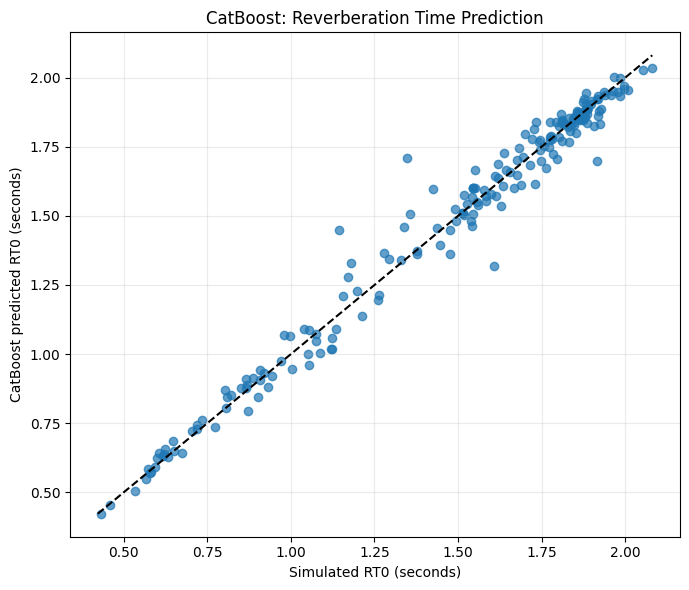

In [11]:
# Check Predicted against Simulated RT
plt.figure(figsize=(7, 6))

plt.scatter(y_test, predictions, alpha=0.7)

low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())

plt.plot([low, high], [low, high], "k--")
plt.xlabel("Simulated RT0 (seconds)")
plt.ylabel("CatBoost predicted RT0 (seconds)")
plt.title("CatBoost: Reverberation Time Prediction")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

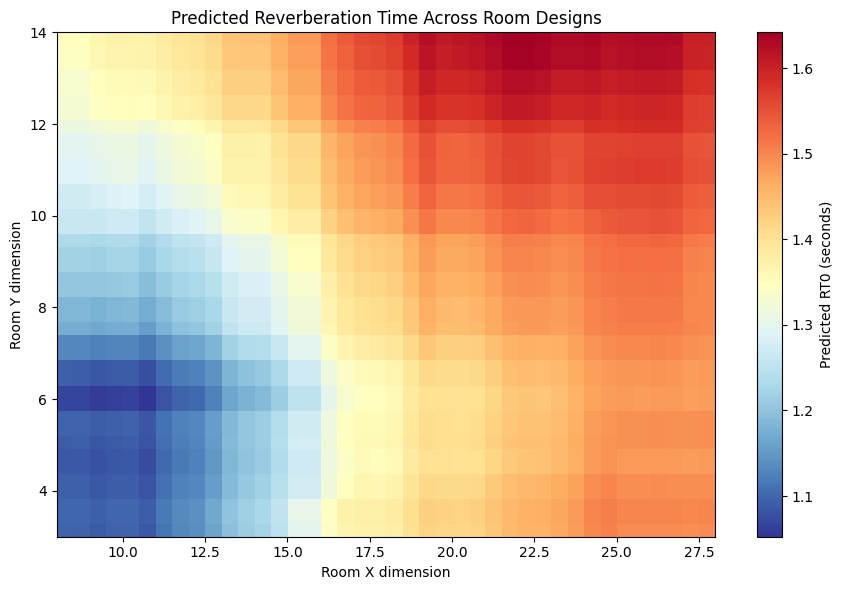

In [12]:
# Explore a design-space heatmap

# Select one existing design as the baseline.
baseline = df.iloc[0]

# Explore the observed ranges of X Dim and Y Dim.
x_values = np.linspace(df["X Dim"].min(),
                       df["X Dim"].max(), 40)
y_values = np.linspace(df["Y Dim"].min(),
                       df["Y Dim"].max(), 40)

grid = pd.DataFrame([
    {**baseline[features].to_dict(), "X Dim": x, "Y Dim": y}
    for y in y_values
    for x in x_values
])

for col in categorical_features:
    grid[col] = grid[col].astype(str)

Z = model.predict(grid[features]).reshape(
    len(y_values), len(x_values)
)

plt.figure(figsize=(9, 6))
plt.imshow(
    Z,
    origin="lower",
    aspect="auto",
    extent=[
        x_values.min(), x_values.max(),
        y_values.min(), y_values.max()
    ],
    cmap="RdYlBu_r"
)
plt.colorbar(label="Predicted RT0 (seconds)")
plt.xlabel("Room X dimension")
plt.ylabel("Room Y dimension")
plt.title("Predicted Reverberation Time Across Room Designs")
plt.tight_layout()
plt.show()

In [15]:
# Export the model for Grasshopper
import json
from google.colab import files

model_path = "/content/catboost_RT0.cbm"
metadata_path = "/content/catboost_RT0_metadata.json"

model.save_model(model_path)

metadata = {
    "target": "RT0",
    "target_units": "seconds",
    "features": features,
    "categorical_features": categorical_features,
    "model_format": "CatBoost CBM",
    "dataset_rows": int(len(df)),
    "training_rows": int(len(X_train)),
    "testing_rows": int(len(X_test)),
    "test_MAE_seconds": float(mae),
    "test_RMSE_seconds": float(rmse),
    "test_R2": float(r2)
}

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

files.download(model_path)
files.download(metadata_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>